SHAP evaluated on 256 training rows.
=== Top 20 Features by SHAP Importance (Random Forest, class 1) ===
                                                   Feature  Mean_SHAP_Value
                       android.permission.READ_PHONE_STATE         0.170364
                com.google.android.c2dm.permission.RECEIVE         0.076599
                 android.permission.RECEIVE_BOOT_COMPLETED         0.056213
          com.android.launcher.permission.INSTALL_SHORTCUT         0.056205
                 android.permission.ACCESS_COARSE_LOCATION         0.041662
                   android.permission.ACCESS_FINE_LOCATION         0.035519
                  android.permission.READ_EXTERNAL_STORAGE         0.029911
                                         total_permissions         0.028810
                    android.permission.SYSTEM_ALERT_WINDOW         0.025584
                              android.permission.GET_TASKS         0.025440
                               com.android.vending.BILLING 

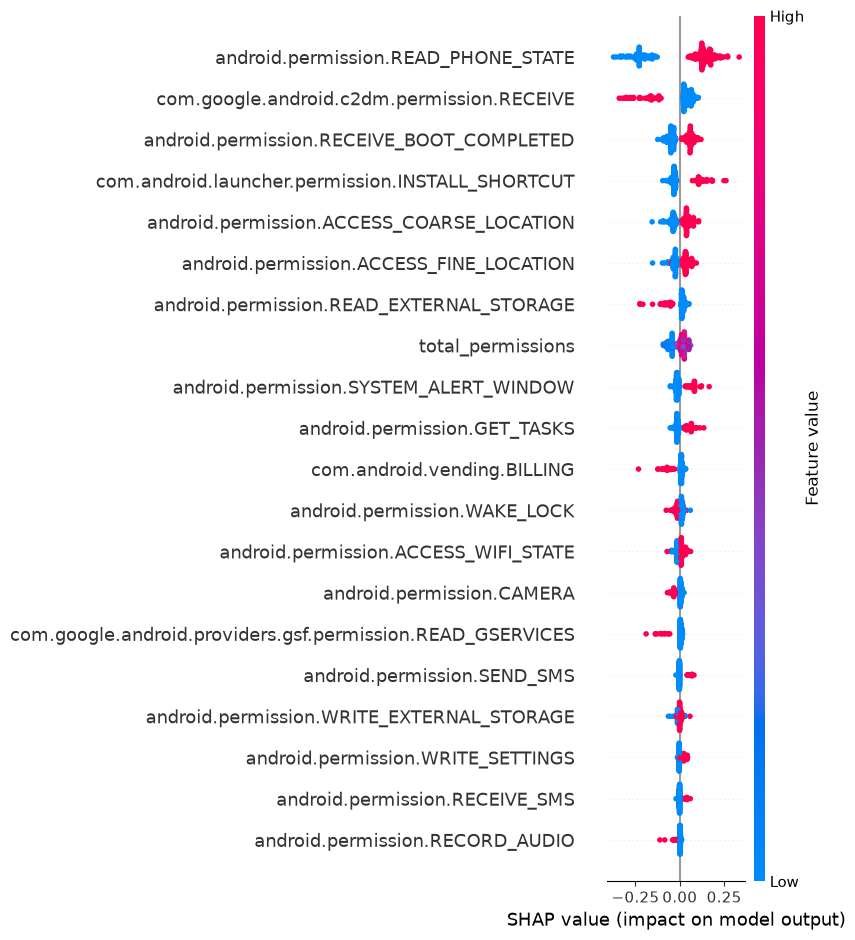

In [3]:
from pathlib import Path
import numpy as np
import pandas as pd
import shap
from sklearn.ensemble import RandomForestClassifier

# Use the fixed training split generated by data_analysis.ipynb.
TRAIN_PATH = Path.cwd() / "train_data.csv"
train_data = pd.read_csv(TRAIN_PATH)

X_train = train_data.drop(columns="Result")
y_train = train_data["Result"]

# Fit only on training data.
model = RandomForestClassifier(n_estimators=100,random_state=42,n_jobs=-1)
model.fit(X_train, y_train)

X_shap = X_train.sample(n=min(256, len(X_train)), random_state=42)
shap_values = shap.TreeExplainer(model)(X_shap)

# Rank by mean absolute SHAP value for the malicious (class 1) label.
if shap_values.values.ndim == 3:
    class_index = list(model.classes_).index(1)
    shap_vals_matrix = shap_values.values[:, :, class_index]
else:
    shap_vals_matrix = shap_values.values

shap_ranking = pd.DataFrame({
    "Feature": X_train.columns,
    "Mean_SHAP_Value": np.abs(shap_vals_matrix).mean(axis=0)
}).sort_values(by="Mean_SHAP_Value", ascending=False).reset_index(drop=True)

top_20_features = shap_ranking.head(20).copy()
shap_features_path = Path.cwd() / "top_20_shap_features.csv"
top_20_features.to_csv(shap_features_path, index=False)
print(f"SHAP evaluated on {len(X_shap):,} training rows.")
print("=== Top 20 Features by SHAP Importance (Random Forest, class 1) ===")
print(top_20_features.to_string(index=False))
print(f"Saved top 20 features to {shap_features_path}")

shap.summary_plot(shap_vals_matrix, X_shap, max_display=20)
